# Guarded Personalization: starter notebook

**Problem.** A wearable model must keep learning each person's normal pattern (bodies change: fitness, a new device,
a new medication, a new routine). If it also learns an **emerging illness** as "normal", it stops detecting it.
We call this **contamination**.

- **Illness = anomaly** → ALERT, never learn it.
- **Healthy lasting change = new normal** → ADAPT (learn it).
- **Short benign blip** (travel, alcohol, stress) → WAIT, no alert.

**Pipeline in this notebook**

1. **Data**: daily resting heart rate (RHR), steps and sleep per person (+ text notes when the dataset has them).
2. **Personal detector**: predicts today's RHR from context; anomaly score = standardized residual.
3. **Safety shield**: a frozen, non-LLM gate with illness-class-conditional split-conformal calibration.
   ADAPT can be executed only when the gate excludes "illness" → P(update | illness) ≤ α for any policy and any LLM.
4. **LLM advisor** (three jobs): reads context text, can **veto** learning (never force it), and gives RL a
   prior via potential-based reward shaping. Its trust is learned from delayed outcomes.
5. **RL agent** (PPO, NumPy) picks ALERT / ADAPT / WAIT / ASK with delayed rewards; λ(t) is a dual variable
   that keeps the illness-update rate inside a risk budget.
6. **Evaluation**: contamination vs. useful-adaptation frontier, coverage check, rule baseline, ablations.

**Datasets (choose in the config cell)**

| # | Dataset | Why it is in the paper | Access |
|---|---|---|---|
| 1 | **Stanford COVID-19 Wearables, Phase 1** (Mishra 2020) | Real COVID episodes with symptom dates; development set | Open |
| 2 | **Stanford COVID-19 Wearables, Phase 2** (Alavi 2022) | Larger real-illness test set; Fitbit + Apple Watch (device shift) | Open |
| 3 | **PMData** (Thambawita 2020) | Real daily wellness / alcohol / training notes → real text context for the LLM; real healthy changes | Open |
| (swap-in) | Evidation 2019–20 (Synapse) | Larger COVID/flu test; replaces #1 if access is approved | Request |

Datasets without enough real illness episodes (PMData, healthy Stanford users) get **injected, labeled events**
(illness ramps, device changes, fitness, medication, travel/alcohol blips) on top of their **real** traces.
Injected results are mechanism tests; clinical claims use real illness episodes only.

**LLMs**: `simulated` (fast, controllable reliability for clean/shuffled/corrupted/drifting tests),
**Llama-3.2-3B-Instruct** (main: best-balanced in our ICSC 2026 paper, small enough for on-device use),
**Qwen2.5-7B-Instruct** (stronger open model, different family), and optionally one API model as an upper
reference. A TF-IDF text classifier on the same text is the non-LLM control.

Run top to bottom. With `DATASET = "simulated"` everything runs on a laptop CPU in a few minutes.

In [1]:
import os, json, time, glob, hashlib, math, copy, warnings
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
warnings.filterwarnings("ignore", category=RuntimeWarning)

CFG = dict(
    # ---------------- data ----------------
    DATASET="simulated",            # "simulated" | "stanford_p1" | "stanford_p2" | "pmdata"
    DATA_DIR="data/stanford_p1",    # folder with the unzipped files
    LABELS_CSV="data/stanford_p1_labels.csv",  # columns: id, symptom_date[, diagnosis_date]
    N_SIM_USERS=160, SIM_DAYS=180,
    INJECT_EVENTS=True,             # add labeled events on real healthy traces
    CALIB_DAYS=28,                  # clean personal-baseline period
    SPLIT=(0.55, 0.15, 0.30),       # person-disjoint train / conformal-calibration / test
    # ---------------- detector / segments ----------------
    TAU_START=2.0, TAU_QUIET=1.5, QUIET_TO_CLOSE=2, ADAPT_WEIGHT=3.0, FORGET=0.97,
    # ---------------- shield ----------------
    ALPHA=0.10,
    # ---------------- LLM advisor ----------------
    LLM_BACKEND="simulated",        # "simulated" | "openai_compatible" | "hf"
    LLM_MODEL="llama-3.2-3b-instruct",
    LLM_BASE_URL="http://localhost:11434/v1",   # Ollama; Groq: https://api.groq.com/openai/v1
    LLM_API_KEY_ENV="GROQ_API_KEY",
    LLM_CACHE="llm_cache.jsonl",
    VETO_P=0.80, VETO_CONF=0.70,    # advisor may close the gate when confident of illness
    SHAPING_KAPPA=1.0,              # potential-based shaping strength (0 = off)
    # ---------------- feedback / costs ----------------
    LABEL_DELAY=3, LABEL_MISSING=0.25,
    ASK_PER_30D=4, USER_RESPONSE=0.75,
    R_DETECT=10.0, R_LEAD_PER_DAY=1.0, R_LEAD_CAP=3, R_MISS=-8.0,
    C_FALSE_ALERT=1.5, C_CONTAM=3.0, B_BENIGN_ADAPT=0.5, C_STALE=0.3, C_ASK=1.0,
    RISK_BUDGET=0.02, LAMBDA0=1.0, LAMBDA_LR=5.0,
    # ---------------- RL ----------------
    PPO_ITERS=80, USERS_PER_ITER=16, SEED=0,
)
QUICK = True   # set False for full-length runs
if not QUICK:
    CFG.update(N_SIM_USERS=400, PPO_ITERS=300, USERS_PER_ITER=24)
rng_global = np.random.default_rng(CFG["SEED"])
ACTIONS = ["ALERT", "ADAPT", "WAIT", "ASK"]
ALERT, ADAPT, WAIT, ASK = range(4)

## 1. Data
Every dataset is converted to the same **daily trace**: date, RHR, steps, sleep hours, free-text note, and
(if known) real illness episodes. Loaders are defensive: a missing file gives NaNs, not a crash.

In [2]:
@dataclass
class Trace:
    uid: str
    dates: pd.DatetimeIndex
    rhr: np.ndarray
    steps: np.ndarray
    sleep: np.ndarray
    notes: list
    illness: list = field(default_factory=list)   # list of dicts: start, end, onset (day indices), source
    source: str = ""

def _daily_rhr_from_minutes(hr: pd.Series, steps: pd.Series, min_rest=60):
    """Resting HR = median HR at minutes with zero steps in the preceding 12 minutes (Mishra et al. 2020)."""
    hr_m = hr.resample("1min").mean()
    st_m = steps.resample("1min").sum().reindex(hr_m.index).fillna(0.0)
    still = st_m.rolling(12, min_periods=1).sum() == 0
    rest = hr_m.where(still)
    g = rest.groupby(rest.index.normalize())
    out = g.median().where(g.count() >= min_rest)
    return out, st_m.groupby(st_m.index.normalize()).sum()

def load_stanford(data_dir, labels_csv=None, pre=7, post=14):
    """Stanford COVID-19 wearables (Phase 1 or 2). Files: <id>_hr.csv (user,datetime,heartrate),
    <id>_steps.csv (user,datetime,steps), optional <id>_sleep.csv (user,datetime,stage_duration,stage).
    Illness window = [symptom - pre, symptom + post). Labels come from the papers' supplementary tables."""
    labels = {}
    if labels_csv and os.path.exists(labels_csv):
        lab = pd.read_csv(labels_csv)
        for _, r in lab.iterrows():
            labels.setdefault(str(r["id"]), []).append(pd.Timestamp(r["symptom_date"]).normalize())
    traces = []
    for hr_path in sorted(glob.glob(os.path.join(data_dir, "**", "*_hr.csv"), recursive=True)):
        uid = os.path.basename(hr_path).replace("_hr.csv", "")
        st_path = hr_path.replace("_hr.csv", "_steps.csv")
        if not os.path.exists(st_path):
            continue
        hr = pd.read_csv(hr_path, usecols=["datetime", "heartrate"], parse_dates=["datetime"]).set_index("datetime")["heartrate"]
        st = pd.read_csv(st_path, usecols=["datetime", "steps"], parse_dates=["datetime"]).set_index("datetime")["steps"]
        rhr, steps = _daily_rhr_from_minutes(hr, st)
        idx = pd.date_range(rhr.index.min(), rhr.index.max(), freq="D")
        sleep = pd.Series(np.nan, index=idx)
        sl_path = hr_path.replace("_hr.csv", "_sleep.csv")
        if os.path.exists(sl_path):
            sl = pd.read_csv(sl_path, parse_dates=["datetime"])
            sl = sl[sl["stage"].astype(str).str.lower() != "wake"]
            key = (sl["datetime"] + pd.Timedelta(hours=12)).dt.normalize()
            sleep = (sl.groupby(key)["stage_duration"].sum() / 3600).reindex(idx)
        tr = Trace(uid, idx, rhr.reindex(idx).to_numpy(float), steps.reindex(idx).to_numpy(float),
                   sleep.to_numpy(float), [""] * len(idx), [], "stanford")
        for sd in labels.get(uid, []):
            if idx[0] <= sd <= idx[-1]:
                on = idx.get_loc(sd)
                tr.illness.append(dict(start=max(0, on - pre), end=min(len(idx), on + post), onset=on, source="real"))
        traces.append(tr)
    return traces

def load_pmdata(data_dir):
    """PMData: pXX/fitbit/{resting_heart_rate,steps,sleep}.json, pXX/pmsys/wellness.csv,
    pXX/googledocs/reporting.csv. Wellness + alcohol + injuries become the text note of each day."""
    traces = []
    for pdir in sorted(glob.glob(os.path.join(data_dir, "p*"))):
        uid = os.path.basename(pdir)
        def jload(name):
            p = os.path.join(pdir, "fitbit", name)
            return json.load(open(p)) if os.path.exists(p) else []
        rhr = {}
        for r in jload("resting_heart_rate.json"):
            v = r.get("value", {}).get("value")
            if v:
                rhr[pd.Timestamp(r["dateTime"]).normalize()] = float(v)
        steps = {}
        for r in jload("steps.json"):
            d = pd.Timestamp(r["dateTime"]).normalize()
            steps[d] = steps.get(d, 0.0) + float(r["value"])
        sleep = {}
        for r in jload("sleep.json"):
            d = pd.Timestamp(r.get("dateOfSleep", r.get("endTime"))).normalize()
            sleep[d] = sleep.get(d, 0.0) + float(r.get("minutesAsleep", 0)) / 60
        if not rhr:
            continue
        idx = pd.date_range(min(rhr), max(rhr), freq="D")
        notes = {d: [] for d in idx}
        wp = os.path.join(pdir, "pmsys", "wellness.csv")
        if os.path.exists(wp):
            w = pd.read_csv(wp)
            for _, r in w.iterrows():
                d = pd.Timestamp(r["effective_time_frame"]).tz_localize(None).normalize()
                if d in notes:
                    parts = [f"{k}={r[k]}" for k in ["fatigue", "mood", "readiness", "stress", "soreness", "sleep_quality"] if k in r and pd.notna(r[k])]
                    notes[d].append("wellness: " + ", ".join(parts))
        rp = os.path.join(pdir, "googledocs", "reporting.csv")
        if os.path.exists(rp):
            rep = pd.read_csv(rp)
            for _, r in rep.iterrows():
                d = pd.Timestamp(r.get("date", r.get("timestamp"))).normalize()
                if d in notes and str(r.get("alcohol_consumed", "")).lower() in ("yes", "true", "1"):
                    notes[d].append("reported alcohol")
        ip = os.path.join(pdir, "pmsys", "injury.csv")
        if os.path.exists(ip):
            inj = pd.read_csv(ip)
            for _, r in inj.iterrows():
                d = pd.Timestamp(r["effective_time_frame"]).tz_localize(None).normalize()
                if d in notes and str(r.get("injuries", "{}")) not in ("{}", "nan"):
                    notes[d].append(f"injury reported: {r['injuries']}")
        tr = Trace(uid, idx, pd.Series(rhr).reindex(idx).to_numpy(float),
                   pd.Series(steps).reindex(idx).to_numpy(float), pd.Series(sleep).reindex(idx).to_numpy(float),
                   ["; ".join(notes[d]) for d in idx], [], "pmdata")
        traces.append(tr)
    return traces

def synthetic_traces(n, days, rng):
    """Healthy daily traces with personal baselines, weekday rhythm, sleep/activity coupling and AR(1) noise."""
    out = []
    for i in range(n):
        idx = pd.date_range("2025-01-01", periods=days, freq="D")
        rhr0, st0, sl0 = rng.normal(62, 7), rng.lognormal(np.log(7500), 0.4), rng.normal(7.0, 0.5)
        wk = (idx.dayofweek >= 5).astype(float)
        logst = np.log(st0) + rng.normal(0, 0.35, days) + wk * rng.uniform(-0.2, 0.3)
        sleep = sl0 + 0.4 * wk + rng.normal(0, 0.6, days)
        e = np.zeros(days)
        for t in range(1, days):
            e[t] = 0.5 * e[t - 1] + rng.normal(0, 1.4)
        prev = np.r_[0, logst[:-1] - np.log(st0)]
        rhr = rhr0 - 0.9 * (sleep - sl0) + 1.0 * prev + e
        out.append(Trace(f"sim{i:04d}", idx, rhr, np.exp(logst), sleep, [""] * days, [], "simulated"))
    return out

### Event injection on real traces
Labeled events are added to traces so every dataset has (a) illness episodes, (b) lasting **benign** shifts
(device, fitness, medication, routine) and (c) short benign **blips** (travel, alcohol, stress).
Notes are written only some of the time (people do not always report), so the LLM sees realistic, partial context.

In [3]:
ILL_NOTES = ["feeling tired", "sore throat", "headache", "feeling feverish", "cough", "body aches"]
BENIGN = {
    "device":     dict(notes=["paired a new watch", "switched to a new tracker"], p_note=0.7),
    "fitness":    dict(notes=["started running", "training for a 5k", "new gym routine"], p_note=0.3),
    "medication": dict(notes=["started new blood-pressure medication", "began metoprolol"], p_note=0.6),
    "routine":    dict(notes=["started a new job, sleeping less", "night shifts this month"], p_note=0.4),
}
BLIP_NOTES = ["flew overseas", "had several drinks", "stressful deadline", "late night out"]

@dataclass
class Stream:
    uid: str
    dates: pd.DatetimeIndex
    rhr: np.ndarray
    steps: np.ndarray
    sleep: np.ndarray
    notes: list
    kind: np.ndarray          # per day: "normal" | "illness" | "drift:<type>" | "blip"
    z: np.ndarray             # 1 = illness day
    events: list
    source: str = ""
    @property
    def T(self): return len(self.rhr)

def _trapezoid(T, s, up, plat, down):
    x = np.zeros(T); t = s
    for k in range(up):   x[min(t, T - 1)] = (k + 1) / (up + 1); t += 1
    for _ in range(plat): x[min(t, T - 1)] = 1.0; t += 1
    for k in range(down): x[min(t, T - 1)] = (down - k) / (down + 1); t += 1
    return x, min(t, T)

def inject(tr: Trace, rng, calib=28, inject_events=True):
    T = len(tr.rhr)
    rhr, steps, sleep = tr.rhr.copy(), tr.steps.copy(), tr.sleep.copy()
    notes = list(tr.notes)
    kind = np.array(["normal"] * T, dtype=object)
    z = np.zeros(T, int)
    events = []
    for e in tr.illness:  # real episodes
        kind[e["start"]:e["end"]] = "illness"; z[e["start"]:e["end"]] = 1
        events.append(dict(type="illness", ill=True, **e))
    if inject_events and T > calib + 40:
        n_ill = 0 if tr.illness else rng.choice([1, 2, 3], p=[0.4, 0.4, 0.2])
        n_drift = rng.choice([0, 1, 2], p=[0.25, 0.5, 0.25])
        n_blip = rng.choice([1, 2, 3, 4])
        plan = [("illness", None)] * n_ill + [("drift", rng.choice(list(BENIGN))) for _ in range(n_drift)] + [("blip", None)] * n_blip
        rng.shuffle(plan)
        used = np.zeros(T, bool); used[:calib + 7] = True
        for typ, sub in plan:
            for _ in range(50):
                s = int(rng.integers(calib + 7, T - 20))
                if not used[max(0, s - 8): s + 22].any(): break
            else:
                continue
            if typ == "illness":
                up, plat, down = int(rng.integers(2, 5)), int(rng.integers(3, 8)), 3
                b, end = _trapezoid(T, s, up, plat, down)
                rhr += b * rng.uniform(4, 9); steps *= 1 - b * rng.uniform(0.3, 0.6); sleep += b * rng.uniform(0.5, 1.2)
                onset = min(T - 1, s + up + int(rng.integers(0, 3)))
                for d in range(s, end):
                    if d >= onset - 1 and rng.random() < 0.5: notes[d] = (notes[d] + "; " if notes[d] else "") + rng.choice(ILL_NOTES)
                kind[s:end] = "illness"; z[s:end] = 1
                events.append(dict(type="illness", ill=True, start=s, end=end, onset=onset, source="injected"))
                used[s:end + 8] = True
            elif typ == "drift":
                L = dict(device=1, fitness=int(rng.integers(30, 46)), medication=int(rng.integers(2, 5)), routine=int(rng.integers(4, 8)))[sub]
                ramp = np.clip((np.arange(T) - s + 1) / L, 0, 1)
                if sub == "device":     rhr += ramp * rng.choice([-1, 1]) * rng.uniform(3, 5)
                if sub == "fitness":    rhr -= ramp * rng.uniform(3, 6); steps *= 1 + 0.35 * ramp
                if sub == "medication": rhr -= ramp * rng.uniform(6, 10)
                if sub == "routine":    rhr += ramp * rng.uniform(3, 5); sleep -= 0.7 * ramp; steps *= 1 - 0.3 * ramp
                end = min(T, s + L + 14)
                for d in range(s, min(T, s + max(L, 3))):
                    if rng.random() < BENIGN[sub]["p_note"] / max(1, L / 3): notes[d] = (notes[d] + "; " if notes[d] else "") + rng.choice(BENIGN[sub]["notes"])
                kind[s:end] = np.where(kind[s:end] == "normal", f"drift:{sub}", kind[s:end])
                events.append(dict(type=f"drift:{sub}", ill=False, start=s, end=end, onset=s, source="injected"))
                used[s:end] = True
            else:
                dur = int(rng.integers(1, 4))
                b, end = _trapezoid(T, s, 0, dur, 1)
                rhr += b * rng.uniform(4, 8); sleep -= b * rng.uniform(0.5, 1.5)
                if rng.random() < 0.7: notes[s] = (notes[s] + "; " if notes[s] else "") + rng.choice(BLIP_NOTES)
                kind[s:end] = np.where(kind[s:end] == "normal", "blip", kind[s:end])
                events.append(dict(type="blip", ill=False, start=s, end=end, onset=s, source="injected"))
                used[s:end + 3] = True
    return Stream(tr.uid, tr.dates, rhr, steps, sleep, notes, kind, z, events, tr.source)

In [4]:
def load_dataset(cfg, rng):
    if cfg["DATASET"] == "simulated":
        traces = synthetic_traces(cfg["N_SIM_USERS"], cfg["SIM_DAYS"], rng)
    elif cfg["DATASET"] in ("stanford_p1", "stanford_p2"):
        traces = load_stanford(cfg["DATA_DIR"], cfg["LABELS_CSV"])
    elif cfg["DATASET"] == "pmdata":
        traces = load_pmdata(cfg["DATA_DIR"])
    else:
        raise ValueError(cfg["DATASET"])
    traces = [t for t in traces if np.isfinite(t.rhr).sum() >= cfg["CALIB_DAYS"] + 30]
    if not traces:
        raise RuntimeError(f"No usable traces found for {cfg['DATASET']} in {cfg['DATA_DIR']}")
    return [inject(t, rng, cfg["CALIB_DAYS"], cfg["INJECT_EVENTS"]) for t in traces]

streams = load_dataset(CFG, rng_global)
perm = rng_global.permutation(len(streams))
n_tr, n_cal = int(CFG["SPLIT"][0] * len(streams)), int(CFG["SPLIT"][1] * len(streams))
TRAIN = [streams[i] for i in perm[:n_tr]]
CALIB = [streams[i] for i in perm[n_tr:n_tr + n_cal]]
TEST = [streams[i] for i in perm[n_tr + n_cal:]]
n_val = max(4, len(TRAIN) // 5)
VAL, TRAIN_RL = TRAIN[:n_val], TRAIN[n_val:]

def summarize(sts):
    ev = [e for s in sts for e in s.events]
    c = pd.Series([e["type"].split(":")[0] for e in ev]).value_counts().to_dict()
    return dict(people=len(sts), days=int(sum(s.T for s in sts)), illness_eps=c.get("illness", 0),
                benign_drifts=c.get("drift", 0), blips=c.get("blip", 0),
                real_illness=sum(e["source"] == "real" for e in ev if e["ill"]),
                notes_frac=round(float(np.mean([bool(n) for s in sts for n in s.notes])), 3))
pd.DataFrame({k: summarize(v) for k, v in dict(train=TRAIN_RL, val=VAL, calib=CALIB, test=TEST).items()}).T

,people,days,illness_eps,benign_drifts,blips,real_illness,notes_frac
train,71.0,12780.0,108.0,48.0,141.0,0.0,0.044
val,17.0,3060.0,23.0,11.0,33.0,0.0,0.045
calib,24.0,4320.0,36.0,17.0,46.0,0.0,0.047
test,48.0,8640.0,66.0,35.0,96.0,0.0,0.043


## 2. Personal detector
Context-aware forecaster of today's RHR (sleep, today's and yesterday's activity, weekend) with exponentially
forgetting ridge statistics, so learning a day costs O(1). **Swap point:** replace with TimesFM + LoRA from the
existing repository; the rest of the notebook only calls `learn(x, y, w)` and `score(x, y)`.

In [5]:
def feats(s: Stream, t: int, base_steps: float):
    ls = np.log(max(s.steps[t], 50)) if np.isfinite(s.steps[t]) else np.log(base_steps)
    lp = np.log(max(s.steps[t - 1], 50)) if t > 0 and np.isfinite(s.steps[t - 1]) else ls
    sl = s.sleep[t] if np.isfinite(s.sleep[t]) else 7.0
    return np.array([1.0, sl - 7.0, ls - 8.8, lp - 8.8, float(s.dates[t].dayofweek >= 5)])

class Detector:
    def __init__(self, forget=0.97, ridge=1.0):
        self.lam, self.ridge = forget, ridge
        self.A = np.zeros((5, 5)); self.b = np.zeros(5); self.c = 0.0; self.n = 0.0; self._fit = None
    def learn(self, x, y, w=1.0):
        d = self.lam ** w
        self.A = d * self.A + w * np.outer(x, x); self.b = d * self.b + w * x * y
        self.c = d * self.c + w * y * y; self.n = d * self.n + w; self._fit = None
    def _solve(self):
        R = self.ridge * np.eye(5); R[0, 0] = 1e-6
        beta = np.linalg.solve(self.A + R, self.b)
        sse = self.c - 2 * beta @ self.b + beta @ self.A @ beta
        self._fit = (beta, math.sqrt(max(sse / max(self.n - 5, 1.0), 0.8 ** 2)))
    def score(self, x, y):
        if self._fit is None: self._solve()
        beta, sd = self._fit
        return (y - x @ beta) / sd
    def predict(self, x):
        if self._fit is None: self._solve()
        return x @ self._fit[0]

## 3. Frozen reference features and the safety shield
The gate must not depend on the policy, otherwise calibration and deployment are not exchangeable.
So the gate reads features from a **reference detector** that only ever learns quiet days ("clean-only"),
computed identically during calibration and deployment.

**Gate.** Logistic model p_ill(x) trained on train users. **Illness-class-conditional split conformal** on
calibration users, **one random decision day per illness episode** (episodes, not correlated days):
nonconformity s = 1 − p_ill. Illness ∈ Γα(x) iff s ≤ q̂, where q̂ is the ⌈(n+1)(1−α)⌉-th smallest calibration score.
ADAPT is executable only if illness ∉ Γα(x) ⇒ **P(update | illness) ≤ α** for any policy and advisor (Prop. 1).

In [6]:
def reference_features(s: Stream, cfg):
    """Policy-independent per-day features from a clean-only detector. Returns (F, score, decision_mask)."""
    T, c0 = s.T, cfg["CALIB_DAYS"]
    det = Detector(cfg["FORGET"])
    ok = np.isfinite(s.rhr)
    base_steps = np.nanmedian(s.steps[:c0]) if np.isfinite(s.steps[:c0]).any() else 7000.0
    base_sleep = np.nanmedian(s.sleep[:c0]) if np.isfinite(s.sleep[:c0]).any() else 7.0
    for t in range(c0):
        if ok[t]: det.learn(feats(s, t, base_steps), s.rhr[t])
    F = np.zeros((T, 9)); score = np.zeros(T); dec = np.zeros(T, bool)
    seg, quiet, zs = False, 0, []
    for t in range(c0, T):
        if not ok[t]: continue
        x = feats(s, t, base_steps); zt = det.score(x, s.rhr[t]); score[t] = zt
        a = abs(zt)
        if not seg and a >= cfg["TAU_START"]: seg, zs, quiet = True, [], 0
        if seg:
            quiet = quiet + 1 if a < cfg["TAU_QUIET"] else 0
            if quiet >= cfg["QUIET_TO_CLOSE"]: seg = False
        if seg:
            zs.append(zt); dec[t] = True
            k = np.arange(len(zs[-7:]))
            slope = np.polyfit(k, zs[-7:], 1)[0] if len(k) >= 2 else 0.0
            st_dev = (np.log(max(s.steps[t], 50)) - np.log(base_steps)) if np.isfinite(s.steps[t]) else 0.0
            sl_dev = (s.sleep[t] - base_sleep) if np.isfinite(s.sleep[t]) else 0.0
            F[t] = [zt / 3, np.mean(zs) / 3, np.max(np.abs(zs)) / 3, min(len(zs), 30) / 30, np.clip(slope, -3, 3) / 3,
                    np.clip(st_dev, -2, 2), np.clip(sl_dev, -4, 4) / 2, np.std(zs) / 3 if len(zs) > 1 else 0, float(zt > 0)]
        else:
            det.learn(x, s.rhr[t])   # clean-only: learn quiet days only
    return F, score, dec

REF = {s.uid: reference_features(s, CFG) for s in streams}

class Shield:
    """Frozen non-LLM gate with illness-class-conditional split-conformal calibration."""
    def __init__(self, train, calib, rng):
        X = np.concatenate([REF[s.uid][0][REF[s.uid][2]] for s in train])
        y = np.concatenate([s.z[REF[s.uid][2]] for s in train])
        self.clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(X, y)
        self.cal_scores = []
        for s in calib:
            F, _, dec = REF[s.uid]
            for e in s.events:
                if not e["ill"]: continue
                days = [d for d in range(e["start"], e["end"]) if dec[d]]
                if days:  # one exchangeable unit per illness episode
                    d = int(rng.choice(days))
                    self.cal_scores.append(1 - self.p_ill(F[d]))
        self.cal_scores = np.sort(np.array(self.cal_scores))
    def p_ill(self, f):
        return float(self.clf.predict_proba(f.reshape(1, -1))[0, 1])
    def p_ill_all(self, F):
        return self.clf.predict_proba(F)[:, 1]
    def threshold(self, alpha):
        """Gate opens iff p_ill < threshold(alpha)."""
        n = len(self.cal_scores)
        k = math.ceil((n + 1) * (1 - alpha))
        if n == 0 or k > n: return -np.inf          # alpha below the achievable grid: gate never opens
        return 1 - self.cal_scores[k - 1]
    def achievable_alphas(self):
        n = len(self.cal_scores)
        return [round(j / (n + 1), 4) for j in range(1, min(n, 10) + 1)]

shield = Shield(TRAIN, CALIB, rng_global)
PGATE = {s.uid: np.where(REF[s.uid][2], shield.p_ill_all(REF[s.uid][0]), 0.0) for s in streams}  # frozen gate scores
print(f"illness calibration episodes: {len(shield.cal_scores)} | smallest achievable alphas: {shield.achievable_alphas()[:5]}")
print(f"gate threshold at alpha={CFG['ALPHA']}: p_ill < {shield.threshold(CFG['ALPHA']):.3f}")

illness calibration episodes: 36 | smallest achievable alphas: [0.027, 0.0541, 0.0811, 0.1081, 0.1351]
gate threshold at alpha=0.1: p_ill < 0.249


## 4. LLM advisor (three jobs)
The advisor sees a **de-identified text summary**: last 7 days of RHR, steps and sleep relative to the person's
baseline, plus any note. It returns strict JSON. Its outputs are used to
**(a)** add context to the RL state, **(b)** veto learning (close the gate; never open it), and
**(c)** shape rewards through a potential function (our ICSC 2026 method), weighted by learned trust.
Advice is precomputed once per candidate day and cached, so experiments never call the LLM twice.

In [7]:
SYSTEM_PROMPT = ("You review a smartwatch wearer's recent vital signs relative to their personal baseline, plus any note "
    "they wrote. Decide if the recent change is more likely an EMERGING ILLNESS (alert, must not be learned as normal) "
    "or BENIGN (a lasting new normal such as fitness, new device, new medication, new routine; or a short blip such as "
    "travel, alcohol, stress). Reply with JSON only: {\"p_illness\": 0-1, \"confidence\": 0-1, "
    "\"question\": \"one short question to ask the wearer\", \"rationale\": \"one sentence\"}")

def summary_text(s: Stream, t: int):
    c0 = CFG["CALIB_DAYS"]
    b_rhr, b_st, b_sl = np.nanmedian(s.rhr[:c0]), np.nanmedian(s.steps[:c0]), np.nanmedian(s.sleep[:c0])
    days = range(max(c0, t - 6), t + 1)
    f = lambda a, fmt: ", ".join("NA" if not np.isfinite(a[d]) else fmt.format(a[d]) for d in days)
    note = " | ".join(s.notes[d] for d in days if s.notes[d]) or "none"
    return (f"Personal baseline: resting HR {b_rhr:.0f} bpm, steps {b_st/1000:.1f}k/day, sleep {b_sl:.1f} h.\n"
            f"Last {len(days)} days (oldest to newest):\n- resting HR: {f(s.rhr, '{:.0f}')}\n"
            f"- steps (k): {f(s.steps / 1000, '{:.1f}')}\n- sleep (h): {f(s.sleep, '{:.1f}')}\nNotes from the wearer: {note}")

class SimulatedAdvisor:
    """Controllable stand-in for an LLM: accurate when an informative note exists, weaker from vitals alone.
    mode: clean | shuffled | corrupted | drifting (good, then unreliable after day 100)."""
    def __init__(self, rng, mode="clean", skill_note=2.2, skill_vitals=0.4):
        self.rng, self.mode, self.sn, self.sv = rng, mode, skill_note, skill_vitals
    def advise(self, s: Stream, t: int):
        c0 = CFG["CALIB_DAYS"]
        has_note = any(s.notes[d] for d in range(max(c0, t - 6), t + 1))
        logit = self.sn if has_note else self.sv
        if self.mode == "drifting" and t > 100: logit = -1.0
        if self.mode == "corrupted": logit = -1.5
        correct = self.rng.random() < 1 / (1 + np.exp(-logit))
        truth = s.z[t] == 1
        says_ill = truth if correct else not truth
        conf = float(np.clip(self.rng.uniform(0.55, 0.95) if has_note else self.rng.uniform(0.5, 0.75), 0, 1))
        p = 0.5 + (conf - 0.5) * (1 if says_ill else -1) + 0.0
        return dict(p_illness=float(np.clip(p, 0.02, 0.98)), confidence=conf, question="targeted")

class LLMAdvisor:
    """Real LLM via an OpenAI-compatible endpoint (Ollama, vLLM, Groq) or local Hugging Face transformers.
    Fails loudly: no silent default values."""
    def __init__(self, backend, model, base_url=None, api_key_env=None, cache=CFG["LLM_CACHE"]):
        self.backend, self.model, self.base_url = backend, model, base_url
        self.key = os.environ.get(api_key_env or "", "")
        self.cache_path, self.cache = cache, {}
        if os.path.exists(cache):
            for line in open(cache):
                r = json.loads(line); self.cache[r["h"]] = r["out"]
        if backend == "hf":
            from transformers import pipeline   # pip install transformers accelerate bitsandbytes
            self.pipe = pipeline("text-generation", model=model, device_map="auto")
    def _call(self, text):
        msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": text}]
        if self.backend == "hf":
            out = self.pipe(msgs, max_new_tokens=160, do_sample=False)[0]["generated_text"][-1]["content"]
            return out
        import urllib.request
        req = urllib.request.Request(self.base_url.rstrip("/") + "/chat/completions",
            data=json.dumps(dict(model=self.model, messages=msgs, temperature=0, max_tokens=160)).encode(),
            headers={"content-type": "application/json", **({"authorization": f"Bearer {self.key}"} if self.key else {})})
        with urllib.request.urlopen(req, timeout=90) as r:
            return json.loads(r.read())["choices"][0]["message"]["content"]
    @staticmethod
    def parse(txt):
        o = json.loads(txt[txt.find("{"): txt.rfind("}") + 1])
        return dict(p_illness=float(np.clip(o["p_illness"], 0, 1)), confidence=float(np.clip(o["confidence"], 0, 1)),
                    question=str(o.get("question", "")))
    def advise(self, s, t):
        text = summary_text(s, t)
        h = hashlib.sha256(f"{self.model}|{text}".encode()).hexdigest()[:24]
        if h in self.cache: return self.cache[h]
        err = None
        for k in range(3):
            try:
                out = self.parse(self._call(text)); break
            except Exception as e:
                err = e; time.sleep(2 ** k)
        else:
            raise RuntimeError(f"LLM failed 3 times: {err}")
        self.cache[h] = out
        with open(self.cache_path, "a") as f: f.write(json.dumps(dict(h=h, out=out)) + "\n")
        return out

def make_advisor(mode="clean", seed=1):
    if CFG["LLM_BACKEND"] == "simulated":
        return SimulatedAdvisor(np.random.default_rng(seed), mode)
    return LLMAdvisor(CFG["LLM_BACKEND"], CFG["LLM_MODEL"], CFG["LLM_BASE_URL"], CFG["LLM_API_KEY_ENV"])

def precompute_advice(sts, advisor, shuffle=False, seed=2):
    """Advice for every candidate decision day (from the policy-independent reference pass)."""
    A = {}
    for s in sts:
        dec = REF[s.uid][2]
        for t in np.flatnonzero(dec):
            A[(s.uid, int(t))] = advisor.advise(s, int(t))
    if shuffle:   # negative control: same advice values, randomly reassigned across days
        keys, vals = list(A), list(A.values())
        np.random.default_rng(seed).shuffle(vals); A = dict(zip(keys, vals))
    return A

ADV = {"clean": precompute_advice(streams, make_advisor("clean"))}
ADV["shuffled"] = precompute_advice(streams, make_advisor("clean"), shuffle=True)
if CFG["LLM_BACKEND"] == "simulated":
    for m in ["corrupted", "drifting"]:
        ADV[m] = precompute_advice(streams, make_advisor(m, seed=3))
ADV["none"] = {}
s0 = TEST[0]; t0 = int(np.flatnonzero(REF[s0.uid][2])[0])
print(summary_text(s0, t0)); print("advice:", ADV["clean"][(s0.uid, t0)])

Personal baseline: resting HR 68 bpm, steps 7.7k/day, sleep 7.1 h.
Last 7 days (oldest to newest):
- resting HR: 70, 67, 67, 68, 67, 70, 74
- steps (k): 5.5, 6.4, 8.0, 11.2, 6.9, 5.4, 7.0
- sleep (h): 7.3, 7.2, 7.6, 6.6, 7.0, 7.7, 7.4
Notes from the wearer: none
advice: {'p_illness': 0.36280275492327096, 'confidence': 0.637197245076729, 'question': 'targeted'}


### Non-LLM text control
Same text, no LLM: TF-IDF + logistic regression trained on train users. If this matches the LLM, the LLM claim
must be dropped.

In [8]:
def text_control_advice(train, all_sts):
    X_txt, y = [], []
    for s in train:
        for t in np.flatnonzero(REF[s.uid][2]):
            X_txt.append(summary_text(s, int(t))); y.append(s.z[t])
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    clf = LogisticRegression(class_weight="balanced", max_iter=2000).fit(vec.fit_transform(X_txt), y)
    A = {}
    for s in all_sts:
        ts = np.flatnonzero(REF[s.uid][2])
        if len(ts) == 0: continue
        p = clf.predict_proba(vec.transform([summary_text(s, int(t)) for t in ts]))[:, 1]
        for t, pi in zip(ts, p):
            A[(s.uid, int(t))] = dict(p_illness=float(pi), confidence=float(0.5 + abs(pi - 0.5)), question="")
    return A
ADV["text_control"] = text_control_advice(TRAIN, streams)

## 5. Environment: shielded decision process
Each day the personal detector scores the vitals. Quiet days are learned automatically. On each day of an open
suspicious segment the agent chooses ALERT / ADAPT / WAIT / ASK. **ADAPT is masked unless the shield is open
(and the advisor has not vetoed)**. Rewards for contamination, staleness and misses arrive with delay.

In [9]:
OBS_DIM = 22

class Env:
    def __init__(self, cfg, shield, alpha, advice, use_shield=True, use_veto=True, learn_trust=True,
                 llm_opens_gate=False, ask_per_30d=None, seed=0):
        self.cfg, self.shield, self.alpha, self.adv = cfg, shield, alpha, advice
        self.use_shield, self.use_veto, self.learn_trust, self.llm_opens = use_shield, use_veto, learn_trust, llm_opens_gate
        self.ask_cap = cfg["ASK_PER_30D"] if ask_per_30d is None else ask_per_30d
        self.thr = shield.threshold(alpha)
        self.rng = np.random.default_rng(seed)
        self.lam = cfg["LAMBDA0"]

    def reset(self, s: Stream):
        c, self.s = self.cfg, s
        self.F, self.refscore, self.refdec = REF[s.uid]
        c0 = c["CALIB_DAYS"]
        self.base_steps = np.nanmedian(s.steps[:c0]) if np.isfinite(s.steps[:c0]).any() else 7000.0
        self.det = Detector(c["FORGET"])
        for t in range(c0):
            if np.isfinite(s.rhr[t]): self.det.learn(feats(s, t, self.base_steps), s.rhr[t])
        self.t, self.done = c0, False
        self.pending, self.reward_acc, self.total_reward = {}, 0.0, 0.0
        self.seg, self.quiet, self.zs = False, 0, []
        self.alpha_tr, self.beta_tr, self.n_rev = 1.0, 1.0, 0
        self.ask_days, self.answer, self.asked_today = [], None, False
        self.adapted_seg = self.alerted_seg = False
        self.last_alert = -999
        T = s.T
        self.u = np.zeros(T, int); self.alert = np.zeros(T, bool); self.asked = np.zeros(T, bool)
        self.decision = np.zeros(T, bool); self.gate_log = np.zeros(T, bool); self.actions = []
        self.detected, self.adv_log = {}, []
        self.ev_of_day = -np.ones(T, int)
        for i, e in enumerate(s.events): self.ev_of_day[e["start"]:e["end"]] = i
        self._ended = set()
        return self._advance()

    # ---------------- helpers ----------------
    def _sched(self, day, r): self.pending[day] = self.pending.get(day, 0.0) + r
    def _give(self, r): self.reward_acc += r; self.total_reward += r
    def trust(self): return self.alpha_tr / (self.alpha_tr + self.beta_tr) if self.learn_trust else 0.5
    def advice(self, t): return self.adv.get((self.s.uid, t))

    def gate_open(self, t):
        if not self.use_shield: return True
        # closed unless the frozen reference flags the day AND the conformal set excludes illness
        g = bool(self.refdec[t]) and PGATE[self.s.uid][t] < self.thr
        a = self.advice(t)
        if self.llm_opens and a is not None and a["p_illness"] < 0.2 and a["confidence"] > 0.7:
            g = True                     # negative control: LLM allowed to open the gate
        if self.use_veto and a is not None and a["p_illness"] >= self.cfg["VETO_P"] and a["confidence"] >= self.cfg["VETO_CONF"]:
            g = False                    # LLM veto: can only close the gate
        return g

    def _day_start(self, t):
        c = self.cfg
        if t in self.pending: self._give(self.pending.pop(t))
        for i, e in enumerate(self.s.events):
            if e["ill"] and e["end"] == t and i not in self._ended:
                self._ended.add(i)
                if i not in self.detected: self._give(c["R_MISS"])
        # delayed, possibly missing label reveals update advisor trust
        for (d, p_ill) in list(self.adv_log):
            if d + c["LABEL_DELAY"] == t:
                self.adv_log.remove((d, p_ill))
                if self.rng.random() < c["LABEL_MISSING"]: continue
                self.n_rev += 1
                if (p_ill >= 0.5) == bool(self.s.z[d]): self.alpha_tr += 1
                else: self.beta_tr += 1

    def _advance(self):
        c, s = self.cfg, self.s
        while self.t < s.T:
            t = self.t
            self._day_start(t)
            if not np.isfinite(s.rhr[t]): self.t += 1; continue
            x = feats(s, t, self.base_steps); zt = self.det.score(x, s.rhr[t])
            self._x, self._y, self._z = x, s.rhr[t], zt
            a = abs(zt)
            if not self.seg and a >= c["TAU_START"]:
                self.seg, self.zs, self.quiet = True, [], 0
                self.adapted_seg = self.alerted_seg = False; self.answer = None
            if self.seg:
                self.quiet = self.quiet + 1 if a < c["TAU_QUIET"] else 0
                if self.quiet >= c["QUIET_TO_CLOSE"]: self.seg = False
            if not self.seg:
                self.det.learn(x, s.rhr[t], 1.0)       # quiet day: learned automatically
                self.t += 1; continue
            self.zs.append(zt); self.decision[t] = True
            self.gate_log[t] = self.gate_open(t)
            self.asked_today = False
            adv = self.advice(t)
            if adv is not None: self.adv_log.append((t, adv["p_illness"]))
            return self.obs()
        self._finish(); return None

    def _finish(self):
        for i, e in enumerate(self.s.events):
            if e["ill"] and i not in self._ended and i not in self.detected: self._give(self.cfg["R_MISS"])
        for r in self.pending.values(): self._give(r)
        self.pending, self.done = {}, True

    def mask(self):
        m = np.ones(4, bool)
        m[ADAPT] = bool(self.gate_log[self.t])
        while self.ask_days and self.ask_days[0] <= self.t - 30: self.ask_days.pop(0)
        m[ASK] = (len(self.ask_days) < self.ask_cap) and not self.asked_today
        return m

    def potential(self):
        """Phi(s): rewards being consistent with trusted advice (thesis Ch. 5 potential-based shaping)."""
        a = self.advice(self.t)
        if a is None or self.cfg["SHAPING_KAPPA"] == 0: return 0.0
        w = self.trust() * a["confidence"] * (a["p_illness"] - 0.5) * 2
        return self.cfg["SHAPING_KAPPA"] * w * (float(self.alerted_seg) - float(self.adapted_seg))

    def obs(self):
        t, zs = self.t, self.zs
        k = np.arange(len(zs[-7:]))
        slope = np.polyfit(k, zs[-7:], 1)[0] if len(k) >= 2 else 0.0
        a = self.advice(t)
        p_gate = PGATE[self.s.uid][t]
        while self.ask_days and self.ask_days[0] <= t - 30: self.ask_days.pop(0)
        return np.array([
            np.clip(self._z, -6, 6) / 3, np.mean(zs) / 3, min(len(zs), 30) / 15, np.clip(slope, -3, 3) / 3,
            p_gate, float(self.gate_log[t]), self.F[t][5], self.F[t][6],
            float(a is not None), (a["p_illness"] - 0.5) * 2 if a else 0.0, a["confidence"] if a else 0.0,
            float(a is not None and a["p_illness"] >= self.cfg["VETO_P"]),
            self.trust() - 0.5, min(self.n_rev / 10, 1.0),
            float(self.answer == "ill"), float(self.answer == "fine"), float(self.asked_today),
            1 - len(self.ask_days) / max(self.ask_cap, 1), float(self.adapted_seg), float(self.alerted_seg),
            min((t - self.last_alert) / 30, 1.0), self.lam / 5,
        ])

    def step(self, action):
        c, s, t = self.cfg, self.s, self.t
        assert not self.done and self.mask()[action], f"invalid action {ACTIONS[action]}"
        self.reward_acc = 0.0
        phi0 = self.potential()
        self.actions.append((t, action))
        if action == ASK:
            self.asked[t] = True; self.ask_days.append(t); self.asked_today = True
            self._give(-c["C_ASK"])
            if self.rng.random() < c["USER_RESPONSE"]:
                a = self.advice(t)
                acc = 0.95 if (a and a.get("question")) else 0.85     # LLM-written question is more informative
                truth = s.z[t] == 1
                self.answer = ("ill" if truth else "fine") if self.rng.random() < acc else ("fine" if truth else "ill")
            else:
                self.answer = "none"
            return self.obs(), self.reward_acc + (self.potential() - phi0), False
        delay = c["LABEL_DELAY"]
        e_i = self.ev_of_day[t]
        if action == ALERT:
            self.alert[t] = True; self.alerted_seg = True; self.last_alert = t
            if s.z[t] == 1:
                if e_i not in self.detected:
                    self.detected[e_i] = t
                    lead = min(c["R_LEAD_CAP"], max(0, s.events[e_i]["onset"] - t))
                    self._give(c["R_DETECT"] + c["R_LEAD_PER_DAY"] * lead)
            else:
                self._give(-c["C_FALSE_ALERT"])
        elif action == ADAPT:
            self.det.learn(self._x, self._y, c["ADAPT_WEIGHT"]); self.u[t] = 1; self.adapted_seg = True
            if s.z[t] == 1: self._sched(t + delay, -self.lam * c["C_CONTAM"])
            elif str(s.kind[t]).startswith("drift"): self._sched(t + delay, c["B_BENIGN_ADAPT"])
        if action != ADAPT and str(s.kind[t]).startswith("drift"):
            self._sched(t + delay + 7, -c["C_STALE"])
        phi1 = self.potential()
        self.t += 1
        o = self._advance()
        gamma_gap = 0.97 ** (self.t - t) if not self.done else 0.0
        return o, self.reward_acc + gamma_gap * phi1 - phi0, self.done

## 6. Baselines and a strong rule policy
All baselines use the same detector, shield, labels and query budget. The rule follows the formalism (Section 6)
and is tuned on **validation users only**.

In [10]:
class Policy:
    name = "policy"
    def act(self, env, obs): raise NotImplementedError

class NoAdaptation(Policy):
    name = "No adaptation"
    def act(self, env, obs): return ALERT if abs(env._z) >= 2.5 else WAIT

class AlwaysAdaptUnshielded(Policy):
    """Naive continual learning: alert on high scores and learn every suspicious day (run with use_shield=False)."""
    name = "Naive continual (no shield)"
    def act(self, env, obs): return ALERT if (abs(env._z) >= 2.5 and not env.alerted_seg) else ADAPT

class ResidualThresholdGate(Policy):
    name = "Residual-threshold gating"
    def act(self, env, obs):
        m = env.mask()
        if abs(env._z) >= 3.0: return ALERT
        return ADAPT if m[ADAPT] else WAIT

class RulePolicy(Policy):
    """ALERT if gate blocks and score high for k windows; ADAPT if gate accepts and the segment is stable for r windows;
    ASK in the uncertainty band; otherwise WAIT."""
    def __init__(self, k=2, r=3, hi=2.5, band=(0.35, 0.65)):
        self.k, self.r, self.hi, self.band = k, r, hi, band
        self.name = f"Rule + shield (k={k}, r={r})"
    def act(self, env, obs):
        m, zs = env.mask(), env.zs
        n_hi = sum(1 for v in zs[-self.k:] if abs(v) >= self.hi)
        if not m[ADAPT] and n_hi >= self.k and not env.alerted_seg: return ALERT
        stable = len(zs) >= self.r and np.std(zs[-self.r:]) < 0.8
        if m[ADAPT] and stable: return ADAPT
        p = obs[4]
        if m[ASK] and self.band[0] <= p <= self.band[1] and env.answer is None: return ASK
        if env.answer == "ill" and not env.alerted_seg: return ALERT
        return WAIT

def run(policy, sts, alpha, advice_key="clean", seed=0, **env_kw):
    out = []
    for i, s in enumerate(sts):
        env = Env(CFG, shield, alpha, ADV[advice_key], seed=seed * 10007 + i, **env_kw)
        o = env.reset(s)
        while not env.done:
            o, _, _ = env.step(policy.act(env, o))
        out.append(env)
    return out

## 7. RL agent: PPO in NumPy (masking, time-aware GAE, λ(t) dual update)
Decisions happen on irregular days, so the discount between decisions is γ^(days elapsed). After each PPO
iteration, λ ← max(0, λ + η·(illness-update rate − budget)): the dynamic reward scaling of our previous work,
now as a dual variable for a risk budget.

In [11]:
class MLP:
    def __init__(self, sizes, rng, out_gain=0.01):
        self.W, self.b = [], []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            g = out_gain if i == len(sizes) - 2 else np.sqrt(2)
            q, _ = np.linalg.qr(rng.normal(size=(max(a, b), max(a, b))))
            self.W.append(g * q[:a, :b].copy()); self.b.append(np.zeros(b))
    def params(self): return self.W + self.b
    def forward(self, x):
        hs, h = [x], x
        for i in range(len(self.W)):
            h = h @ self.W[i] + self.b[i]
            if i < len(self.W) - 1: h = np.tanh(h)
            hs.append(h)
        return h, hs
    def backward(self, hs, g):
        L = len(self.W); gW, gb = [None] * L, [None] * L
        for i in reversed(range(L)):
            gW[i] = hs[i].T @ g; gb[i] = g.sum(0)
            if i > 0: g = (g @ self.W[i].T) * (1 - hs[i] ** 2)
        return gW + gb

class Adam:
    def __init__(self, params, lr):
        self.p, self.lr, self.k = params, lr, 0
        self.m = [np.zeros_like(x) for x in params]; self.v = [np.zeros_like(x) for x in params]
    def step(self, grads):
        self.k += 1
        for i, (p, g) in enumerate(zip(self.p, grads)):
            self.m[i] = 0.9 * self.m[i] + 0.1 * g; self.v[i] = 0.999 * self.v[i] + 0.001 * g * g
            p -= self.lr * (self.m[i] / (1 - 0.9 ** self.k)) / (np.sqrt(self.v[i] / (1 - 0.999 ** self.k)) + 1e-8)

def masked_softmax(logits, mask):
    z = np.where(mask, logits, -1e9); z = z - z.max(-1, keepdims=True)
    e = np.exp(z) * mask
    return e / e.sum(-1, keepdims=True)

class PPO(Policy):
    name = "RL + shield (ours)"
    def __init__(self, seed=0, hidden=64, lr=1e-3, clip=0.2, ent=0.02, gamma=0.97, lam=0.95, epochs=4, mb=256):
        self.rng = np.random.default_rng(seed)
        self.pi = MLP([OBS_DIM, hidden, hidden, 4], self.rng, 0.01)
        self.vf = MLP([OBS_DIM, hidden, hidden, 1], self.rng, 1.0)
        self.opi, self.ovf = Adam(self.pi.params(), lr), Adam(self.vf.params(), lr)
        self.clip, self.ent, self.gamma, self.lam, self.epochs, self.mb = clip, ent, gamma, lam, epochs, mb
        self.greedy = True
    def probs(self, o, m): return masked_softmax(self.pi.forward(o[None])[0], m[None])[0]
    def act(self, env, obs):
        p = self.probs(obs, env.mask())
        return int(np.argmax(p)) if self.greedy else int(self.rng.choice(4, p=p))
    def gae(self, r, v, days):
        n = len(r); adv = np.zeros(n); last = 0.0
        for i in reversed(range(n)):
            nv, disc = (0.0, 0.0) if i == n - 1 else (v[i + 1], self.gamma ** max(days[i + 1] - days[i], 0))
            delta = r[i] + disc * nv - v[i]; last = delta + disc * self.lam * last; adv[i] = last
        return adv, adv + np.array(v)
    def update(self, B):
        obs, msk, act, oldlp, adv, ret = B["obs"], B["mask"], B["act"], B["logp"], B["adv"], B["ret"]
        adv = (adv - adv.mean()) / (adv.std() + 1e-8); N = len(act)
        for _ in range(self.epochs):
            for s0 in range(0, N, self.mb):
                ix = self.rng.permutation(N)[:self.mb] if N > self.mb else np.arange(N)
                logits, hs = self.pi.forward(obs[ix]); p = masked_softmax(logits, msk[ix])
                lpa = np.log(np.where(msk[ix], p, 1.0)); n = len(ix)
                lp = lpa[np.arange(n), act[ix]]; ratio = np.exp(lp - oldlp[ix]); A = adv[ix]
                ent = -(p * lpa).sum(-1)
                active = ~(((A > 0) & (ratio > 1 + self.clip)) | ((A < 0) & (ratio < 1 - self.clip)))
                dlogp = np.where(active, -A * ratio, 0.0) / n
                onehot = np.zeros_like(p); onehot[np.arange(n), act[ix]] = 1
                g = dlogp[:, None] * (onehot - p) - self.ent * (-p * (lpa + ent[:, None])) / n
                g = np.where(msk[ix], g, 0.0)
                gr = self.pi.backward(hs, g); nrm = np.sqrt(sum((x ** 2).sum() for x in gr))
                self.opi.step([x * min(1, 0.5 / (nrm + 1e-8)) for x in gr])
                v, hv = self.vf.forward(obs[ix])
                gv = self.vf.backward(hv, 0.5 * (v[:, 0] - ret[ix])[:, None] / n)
                nrm = np.sqrt(sum((x ** 2).sum() for x in gv))
                self.ovf.step([x * min(1, 0.5 / (nrm + 1e-8)) for x in gv])

def train_rl(alpha, advice_key="clean", seed=0, iters=None, log_every=10, **env_kw):
    agent, lam, hist = PPO(seed=seed), CFG["LAMBDA0"], []
    rng = np.random.default_rng(seed); agent.greedy = False
    iters = iters or CFG["PPO_ITERS"]
    t0 = time.time()
    for it in range(iters):
        B = {k: [] for k in ["obs", "mask", "act", "logp", "adv", "ret"]}
        rets, ill_days, ill_upd = [], 0, 0
        for j in rng.choice(len(TRAIN_RL), CFG["USERS_PER_ITER"]):
            env = Env(CFG, shield, alpha, ADV[advice_key], seed=int(rng.integers(1e9)), **env_kw); env.lam = lam
            o = env.reset(TRAIN_RL[j]); O, M, A, L, V, R, D = [], [], [], [], [], [], []
            while not env.done:
                m = env.mask(); p = agent.probs(o, m); a = int(rng.choice(4, p=p))
                O.append(o); M.append(m); A.append(a); L.append(np.log(p[a] + 1e-12))
                V.append(float(agent.vf.forward(o[None])[0][0, 0])); D.append(env.t)
                o, r, _ = env.step(a); R.append(r)
            rets.append(env.total_reward)
            ill_days += int(env.decision[env.s.z == 1].sum()); ill_upd += int(env.u[env.s.z == 1].sum())
            if A:
                adv, ret = agent.gae(R, V, D)
                for k, v in zip(["obs", "mask", "act", "logp"], [O, M, A, L]): B[k] += v
                B["adv"] += list(adv); B["ret"] += list(ret)
        agent.update({k: np.array(v) for k, v in B.items()})
        rate = ill_upd / max(ill_days, 1)
        lam = max(0.0, lam + CFG["LAMBDA_LR"] * (rate - CFG["RISK_BUDGET"]))   # dual update of lambda(t)
        agent.ent = 0.02 * (1 - it / iters) + 0.002
        hist.append(dict(it=it, ret=float(np.mean(rets)), illness_update_rate=rate, lam=lam))
        if it % log_every == 0 or it == iters - 1:
            print(f"it {it:3d} return {np.mean(rets):7.2f} illness-update rate {rate:.3f} lambda {lam:.2f}  ({time.time()-t0:.0f}s)")
    agent.greedy = True
    return agent, pd.DataFrame(hist)

agent, hist = train_rl(CFG["ALPHA"])

it   0 return  -19.38 illness-update rate 0.014 lambda 0.97  (0s)


it  10 return    7.33 illness-update rate 0.024 lambda 0.99  (4s)


it  20 return   12.77 illness-update rate 0.013 lambda 0.87  (7s)


it  30 return   13.67 illness-update rate 0.014 lambda 0.88  (10s)


it  40 return   12.12 illness-update rate 0.040 lambda 0.70  (13s)


it  50 return   16.52 illness-update rate 0.015 lambda 0.55  (16s)


it  60 return   16.58 illness-update rate 0.025 lambda 0.38  (20s)


it  70 return   14.17 illness-update rate 0.027 lambda 0.31  (23s)


it  79 return   14.29 illness-update rate 0.024 lambda 0.23  (26s)


## 8. Evaluation
Primary metrics (formalism Section 5), with **person-level bootstrap 95% CIs**:
contamination (illness-update rate and contaminated updates per illness episode), useful adaptation
(share of benign drifts adapted and delay), early warning (episode sensitivity, lead days, false alerts / 30 days)
and human cost (ASK / 30 days).

In [12]:
def user_metrics(env):
    s, c0 = env.s, CFG["CALIB_DAYS"]
    days = max(s.T - c0, 1)
    ill = [e for e in s.events if e["ill"]]
    drifts = [e for e in s.events if e["type"].startswith("drift")]
    delays, adapted = [], 0
    for e in drifts:
        ups = np.flatnonzero(env.u[e["start"]:e["end"]])
        if len(ups): adapted += 1; delays.append(int(ups[0]))
    leads = [e["onset"] - env.detected[i] for i, e in enumerate(s.events) if e["ill"] and i in env.detected]
    return dict(ill_days=int(env.decision[s.z == 1].sum()), ill_updates=int(env.u[s.z == 1].sum()),
                ill_eps=len(ill), contaminated_eps=sum(env.u[e["start"]:e["end"]].any() for e in ill),
                detected_eps=sum(env.alert[e["start"]:e["end"]].any() for e in ill),
                drifts=len(drifts), adapted=adapted, delays=delays, leads=leads,
                false_alerts=int((env.alert & (s.z == 0)).sum()), asks=int(env.asked.sum()), days=days,
                benign_updates=int(env.u[s.z == 0].sum()))

def aggregate(ms):
    S = lambda k: sum(m[k] for m in ms)
    d = S("days")
    return {"illness-update rate": S("ill_updates") / max(S("ill_days"), 1),
            "contaminated episodes": S("contaminated_eps") / max(S("ill_eps"), 1),
            "illness sensitivity": S("detected_eps") / max(S("ill_eps"), 1),
            "lead days": float(np.mean([x for m in ms for x in m["leads"]])) if any(m["leads"] for m in ms) else np.nan,
            "benign drifts adapted": S("adapted") / max(S("drifts"), 1),
            "adaptation delay (d)": float(np.mean([x for m in ms for x in m["delays"]])) if any(m["delays"] for m in ms) else np.nan,
            "false alerts / 30d": 30 * S("false_alerts") / d, "ASK / 30d": 30 * S("asks") / d}

def evaluate(envs, n_boot=500, seed=0):
    ms = [user_metrics(e) for e in envs]
    point = aggregate(ms)
    rng = np.random.default_rng(seed)
    boots = [aggregate([ms[i] for i in rng.integers(0, len(ms), len(ms))]) for _ in range(n_boot)]
    ci = {k: (np.nanpercentile([b[k] for b in boots], 2.5), np.nanpercentile([b[k] for b in boots], 97.5)) for k in point}
    return point, ci

def table(rows):
    df = pd.DataFrame({name: {k: f"{p[k]:.3f} [{ci[k][0]:.2f}, {ci[k][1]:.2f}]" for k in p} for name, (p, ci) in rows.items()}).T
    return df

# tune the rule on validation users (maximize benign adaptation at matched safety, penalize alerts)
best = None
for k in [1, 2, 3]:
    for r in [2, 3, 5, 7]:
        p, _ = evaluate(run(RulePolicy(k, r), VAL, CFG["ALPHA"]), n_boot=1)
        score = p["illness sensitivity"] + p["benign drifts adapted"] - 0.1 * p["false alerts / 30d"] - p["illness-update rate"]
        if best is None or score > best[0]: best = (score, k, r)
rule = RulePolicy(best[1], best[2])
print("tuned rule:", rule.name)

A = CFG["ALPHA"]
results = {
    "No adaptation": evaluate(run(NoAdaptation(), TEST, A)),
    "Naive continual (no shield)": evaluate(run(AlwaysAdaptUnshielded(), TEST, A, use_shield=False, use_veto=False)),
    "Residual-threshold gating": evaluate(run(ResidualThresholdGate(), TEST, A)),
    rule.name: evaluate(run(rule, TEST, A)),
    "RL + shield (ours)": evaluate(run(agent, TEST, A)),
}
main_table = table(results); main_table

tuned rule: Rule + shield (k=3, r=2)


,illness-update rate,contaminated episodes,illness sensitivity,lead days,benign drifts adapted,adaptation delay (d),false alerts / 30d,ASK / 30d
No adaptation,"0.000 [0.00, 0.00]","0.000 [0.00, 0.00]","0.970 [0.92, 1.00]","2.413 [1.97, 2.85]","0.000 [0.00, 0.00]","nan [nan, nan]","6.727 [5.46, 8.20]","0.000 [0.00, 0.00]"
Naive continual (no shield),"0.851 [0.82, 0.87]","0.833 [0.74, 0.91]","0.591 [0.48, 0.70]","1.897 [1.26, 2.45]","0.714 [0.54, 0.87]","5.760 [2.79, 9.55]","0.448 [0.37, 0.53]","0.000 [0.00, 0.00]"
Residual-threshold gating,"0.024 [0.01, 0.04]","0.182 [0.09, 0.27]","0.879 [0.79, 0.96]","1.965 [1.61, 2.36]","0.886 [0.80, 0.97]","4.710 [2.89, 6.69]","0.859 [0.64, 1.12]","0.000 [0.00, 0.00]"
"Rule + shield (k=3, r=2)","0.016 [0.01, 0.03]","0.106 [0.04, 0.18]","0.894 [0.82, 0.96]","0.897 [0.51, 1.30]","0.886 [0.79, 0.97]","7.226 [4.67, 9.91]","0.119 [0.07, 0.18]","0.847 [0.73, 0.98]"
RL + shield (ours),"0.027 [0.01, 0.04]","0.182 [0.10, 0.27]","0.970 [0.93, 1.00]","2.063 [1.70, 2.42]","0.829 [0.70, 0.96]","5.172 [3.02, 7.26]","0.181 [0.13, 0.23]","0.000 [0.00, 0.00]"


### Figure 1: contamination vs. useful-adaptation frontier
Each point is one α. A better method sits **left** (less contamination) and **up** (more benign adaptation).
(The RL policy here was trained at a single α; for the paper, retrain per α.)

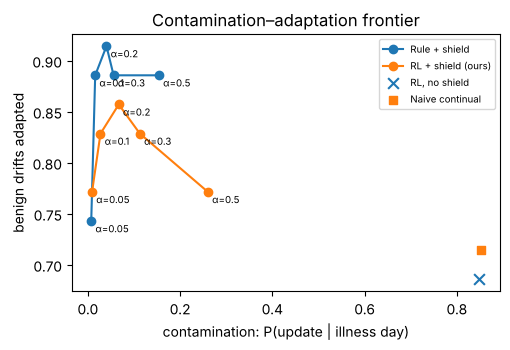

In [13]:
alphas = [a for a in [0.05, 0.1, 0.2, 0.3, 0.5] if shield.threshold(a) > -np.inf] or [CFG["ALPHA"]]
front = {"Rule + shield": [], "RL + shield (ours)": [], "RL, no shield": []}
for a in alphas:
    front["Rule + shield"].append(evaluate(run(rule, TEST, a), n_boot=1)[0])
    front["RL + shield (ours)"].append(evaluate(run(agent, TEST, a), n_boot=1)[0])
p_ns = evaluate(run(agent, TEST, CFG["ALPHA"], use_shield=False), n_boot=1)[0]
p_naive = results["Naive continual (no shield)"][0]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for name, pts in front.items():
    if not pts: continue
    ax.plot([p["illness-update rate"] for p in pts], [p["benign drifts adapted"] for p in pts], "o-", label=name)
    for a, p in zip(alphas, pts): ax.annotate(f"α={a}", (p["illness-update rate"], p["benign drifts adapted"]), fontsize=7, xytext=(3, -8), textcoords="offset points")
ax.scatter([p_ns["illness-update rate"]], [p_ns["benign drifts adapted"]], marker="x", s=60, label="RL, no shield")
ax.scatter([p_naive["illness-update rate"]], [p_naive["benign drifts adapted"]], marker="s", s=40, label="Naive continual")
ax.set_xlabel("contamination: P(update | illness day)"); ax.set_ylabel("benign drifts adapted"); ax.legend(fontsize=7)
ax.set_title("Contamination–adaptation frontier"); plt.tight_layout(); plt.show()

### Figure 2: does the safety guarantee hold?
Observed P(update | illness) on **held-out people** must stay at or below α (dashed line). Small calibration
sets make the achievable α grid coarse, so CIs are wide on real data.

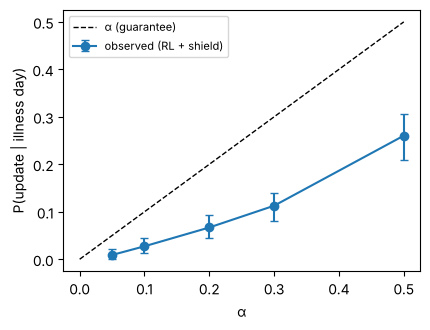

In [14]:
obs_rate, lo, hi = [], [], []
for a in alphas:
    p, ci = evaluate(run(agent, TEST, a), n_boot=300)
    obs_rate.append(p["illness-update rate"]); lo.append(ci["illness-update rate"][0]); hi.append(ci["illness-update rate"][1])
fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.plot([0, max(alphas)], [0, max(alphas)], "k--", lw=1, label="α (guarantee)")
ax.errorbar(alphas, obs_rate, yerr=[np.array(obs_rate) - lo, np.array(hi) - obs_rate], fmt="o-", capsize=3, label="observed (RL + shield)")
ax.set_xlabel("α"); ax.set_ylabel("P(update | illness day)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Ablations: does each LLM role earn its place?
Same trained agent evaluated with different advice sources (for the paper, also retrain per setting).
**Shuffled** and **text control** are the key negative controls; **LLM opens gate** shows why the LLM must
never be allowed to open the gate (coverage breaks under bad advice).

In [15]:
abl = {
    "Full (clean advice)": evaluate(run(agent, TEST, A, "clean")),
    "No LLM": evaluate(run(agent, TEST, A, "none", use_veto=False)),
    "Shuffled advice": evaluate(run(agent, TEST, A, "shuffled")),
    "Text control (TF-IDF)": evaluate(run(agent, TEST, A, "text_control")),
    "Frozen trust": evaluate(run(agent, TEST, A, "clean", learn_trust=False)),
    "No LLM veto": evaluate(run(agent, TEST, A, "clean", use_veto=False)),
}
if "corrupted" in ADV:
    abl["Corrupted advice"] = evaluate(run(agent, TEST, A, "corrupted"))
    abl["Drifting advice"] = evaluate(run(agent, TEST, A, "drifting"))
    abl["Corrupted + LLM opens gate (negative control)"] = evaluate(run(agent, TEST, A, "corrupted", llm_opens_gate=True))
ablation_table = table(abl); ablation_table

,illness-update rate,contaminated episodes,illness sensitivity,lead days,benign drifts adapted,adaptation delay (d),false alerts / 30d,ASK / 30d
Full (clean advice),"0.027 [0.01, 0.04]","0.182 [0.10, 0.27]","0.970 [0.93, 1.00]","2.063 [1.70, 2.42]","0.829 [0.70, 0.96]","5.172 [3.02, 7.26]","0.181 [0.13, 0.23]","0.000 [0.00, 0.00]"
No LLM,"0.035 [0.02, 0.05]","0.242 [0.16, 0.33]","0.970 [0.93, 1.00]","2.556 [2.24, 2.91]","0.829 [0.70, 0.96]","5.103 [2.96, 7.21]","0.917 [0.71, 1.15]","0.000 [0.00, 0.00]"
Shuffled advice,"0.033 [0.02, 0.05]","0.227 [0.14, 0.32]","0.955 [0.90, 1.00]","1.919 [1.58, 2.26]","0.857 [0.73, 0.97]","5.233 [3.19, 7.25]","0.218 [0.16, 0.28]","0.000 [0.00, 0.00]"
Text control (TF-IDF),"0.011 [0.00, 0.02]","0.091 [0.03, 0.16]","0.970 [0.93, 1.00]","1.460 [0.98, 1.89]","0.829 [0.70, 0.96]","5.103 [2.96, 7.21]","0.132 [0.09, 0.18]","0.000 [0.00, 0.00]"
Frozen trust,"0.027 [0.01, 0.04]","0.182 [0.10, 0.27]","0.970 [0.93, 1.00]","2.063 [1.70, 2.42]","0.829 [0.70, 0.96]","5.172 [3.02, 7.26]","0.189 [0.14, 0.24]","0.000 [0.00, 0.00]"
No LLM veto,"0.035 [0.02, 0.05]","0.242 [0.16, 0.33]","0.970 [0.93, 1.00]","2.063 [1.70, 2.42]","0.829 [0.70, 0.96]","5.103 [2.96, 7.21]","0.181 [0.13, 0.23]","0.000 [0.00, 0.00]"
Corrupted advice,"0.033 [0.02, 0.05]","0.227 [0.14, 0.31]","0.939 [0.89, 0.98]","1.902 [1.49, 2.25]","0.829 [0.70, 0.96]","5.552 [3.44, 7.57]","0.284 [0.21, 0.36]","0.000 [0.00, 0.00]"
Drifting advice,"0.029 [0.01, 0.05]","0.197 [0.11, 0.29]","0.955 [0.90, 1.00]","2.000 [1.62, 2.34]","0.829 [0.70, 0.96]","5.379 [3.20, 7.38]","0.243 [0.18, 0.30]","0.000 [0.00, 0.00]"
Corrupted + LLM opens gate (negative control),"0.217 [0.18, 0.25]","0.788 [0.70, 0.87]","0.894 [0.81, 0.97]","1.810 [1.39, 2.22]","0.800 [0.68, 0.92]","7.321 [4.18, 11.05]","0.238 [0.17, 0.31]","0.000 [0.00, 0.00]"


### Figure 3: one person, end to end

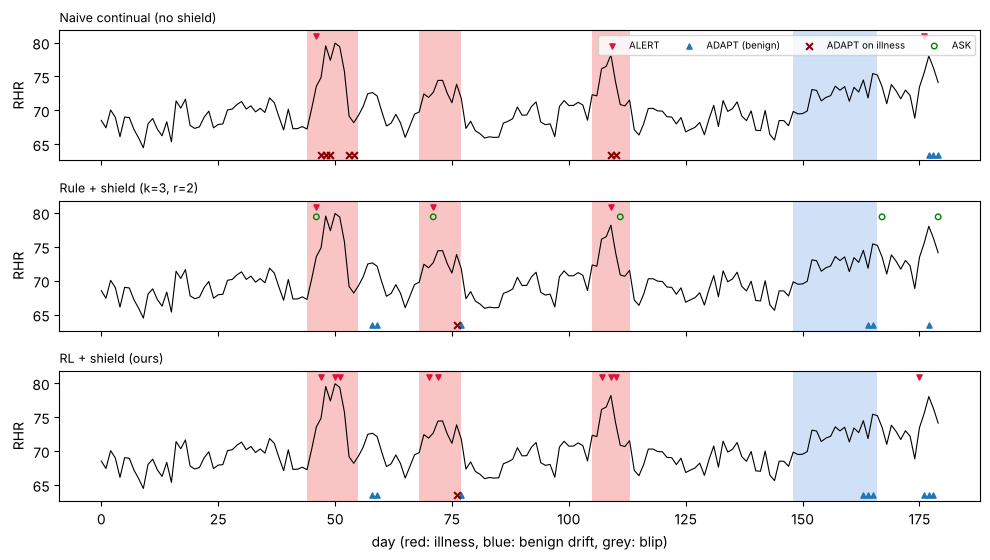

In [16]:
def plot_person(s, policies, alpha=CFG["ALPHA"]):
    fig, axes = plt.subplots(len(policies), 1, figsize=(10, 1.9 * len(policies)), sharex=True)
    for ax, (name, pol, kw) in zip(np.atleast_1d(axes), policies):
        env = Env(CFG, shield, alpha, ADV["clean"], seed=7, **kw); o = env.reset(s)
        while not env.done: o, _, _ = env.step(pol.act(env, o))
        t = np.arange(s.T)
        for e in s.events:
            col = "#f8c4c4" if e["ill"] else ("#cfe0f7" if e["type"].startswith("drift") else "#eeeeee")
            ax.axvspan(e["start"], e["end"], color=col, lw=0)
        ax.plot(t, s.rhr, color="k", lw=0.8)
        top, bot = np.nanmax(s.rhr) + 1, np.nanmin(s.rhr) - 1
        ax.scatter(np.flatnonzero(env.alert), [top] * env.alert.sum(), marker="v", color="crimson", s=14, label="ALERT")
        ax.scatter(np.flatnonzero(env.u & (s.z == 0)), [bot] * int((env.u & (s.z == 0)).sum()), marker="^", color="tab:blue", s=14, label="ADAPT (benign)")
        bad = np.flatnonzero(env.u & (s.z == 1))
        ax.scatter(bad, [bot] * len(bad), marker="x", color="darkred", s=24, label="ADAPT on illness")
        ax.scatter(np.flatnonzero(env.asked), [top - 1.5] * env.asked.sum(), marker="o", facecolors="none", edgecolors="green", s=16, label="ASK")
        ax.set_ylabel("RHR"); ax.set_title(name, loc="left", fontsize=9)
    np.atleast_1d(axes)[0].legend(fontsize=7, ncol=4, loc="upper right")
    np.atleast_1d(axes)[-1].set_xlabel("day (red: illness, blue: benign drift, grey: blip)")
    plt.tight_layout(); plt.show()

pick = next((s for s in TEST if any(e["ill"] for e in s.events) and any(e["type"].startswith("drift") for e in s.events)), TEST[0])
plot_person(pick, [("Naive continual (no shield)", AlwaysAdaptUnshielded(), dict(use_shield=False, use_veto=False)),
                   (rule.name, rule, {}), ("RL + shield (ours)", agent, {})])

## 9. Next steps
1. **Real data**: set `DATASET` to `stanford_p1`, `stanford_p2` or `pmdata` and point `DATA_DIR` to the unzipped
   files. For Stanford, build `LABELS_CSV` (id, symptom_date) from the papers' supplementary tables.
   Report real illness episodes separately from injected ones.
2. **Real LLM**: `LLM_BACKEND="openai_compatible"` with Ollama (`ollama pull llama3.2:3b`, model `llama3.2:3b`)
   or Groq (`GROQ_API_KEY`, model e.g. `llama-3.1-8b-instant`), or `"hf"` with
   `meta-llama/Llama-3.2-3B-Instruct` / `Qwen/Qwen2.5-7B-Instruct`. Advice is cached in `llm_cache.jsonl`.
3. **Detector**: replace `Detector` with TimesFM + LoRA from the existing repo (keep `learn` / `score`).
4. **October go/no-go**: compare RL vs. the tuned rule at matched contamination, with label delays 1/3/7,
   ASK caps 0 / 1 per 30 d / 1 per 7 d, missing responses and drifting advice; 5 seeds; paired tests.